# 5_2 노트북: 분류와 앙상블 회귀

이 복사본은 각 코드 셀 앞에 파이썬 초보자를 위한 한국어 주석을 추가했습니다. 앞부분은 유방암 데이터의 로지스틱 회귀 분류, 뒷부분은 캘리포니아 주택 가격의 회귀 및 여러 트리 모델 비교를 다룹니다.

파일은 UTF-8로 저장했습니다. 원본의 출력은 유지했습니다. 설명을 위해 코드상의 점수 계산 및 예측선 관련 주의점도 해당 셀에 적었습니다.

In [1]:
# 1. 로지스틱 회귀 분류 예제에 필요한 자료와 도구를 불러옵니다.


import pandas as pd
import matplotlib.pyplot as plt
# load_breast_cancer는 유방 종양 측정값과 악성/양성 정답을 담은 학습용 데이터를 제공합니다.
from sklearn.datasets import load_breast_cancer

# LogisticRegression은 이름에 Regression이 있지만, 여기서는 두 종류를 나누는 분류 모델입니다.
from sklearn.linear_model import LogisticRegression

# cancer 객체에는 입력 데이터 cancer.data, 정답 cancer.target, 열 이름 등이 들어 있습니다.
cancer = load_breast_cancer()



In [2]:
# 2. 입력값의 크기를 맞춘 뒤 학습용과 시험용 데이터로 나눕니다.
# random_state를 고정하면 분할 결과가 반복 실행마다 같아집니다.

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# StandardScaler는 각 열을 평균 0, 표준편차 1에 가깝게 변환합니다.
# 특성 단위가 제각각이면 일부 값이 학습을 과도하게 좌우할 수 있어 스케일 조정이 유용합니다.
scaler = StandardScaler()
# fit_transform은 평균/표준편차를 데이터에서 계산(fit)하고, 그 기준으로 변환(transform)합니다.
data_scaled = scaler.fit_transform(cancer . data)


# train_test_split은 데이터를 분리합니다. test_size=0.3은 30%를 시험용으로 남긴다는 뜻입니다.

X_train , X_test , y_train , y_test  = train_test_split(data_scaled, cancer.target, test_size=0.3, random_state= 42)

# 주의: 스케일러를 분할 전에 전체 데이터에 fit하면 시험 데이터 정보가 변환 기준에 섞입니다.
# 엄밀한 평가에서는 분할 후 학습 부분에만 fit하고, 시험 부분은 transform만 해야 합니다.

In [3]:
# 3. 로지스틱 회귀 모델을 학습하고 시험 데이터에서 분류 성능을 계산합니다.

# accuracy_score는 전체 예측 중 정답을 맞힌 비율입니다.
# roc_auc_score는 모델의 점수로 양성과 음성을 얼마나 잘 순서화하는지 평가합니다.
from sklearn.metrics import accuracy_score, roc_auc_score

lr_clf = LogisticRegression() # solver = "lbfgs"

# fit은 학습, predict는 각 표본의 최종 분류(0 또는 1)를 예측합니다.
# predict_proba는 클래스별 확률을 돌려줍니다. [:, 1]은 두 번째 클래스(레이블 1)의 확률입니다.
lr_clf.fit(X_train,y_train)
lr_pred = lr_clf.predict(X_test)
lr_pred_proba = lr_clf.predict_proba(X_test)[: , 1]

print(accuracy_score(y_test,lr_pred), roc_auc_score(y_test, lr_pred_proba))

# 분류 기준값을 바꾸어도 비교할 수 있도록 ROC AUC에는 레이블 대신 확률을 전달합니다.
# 데이터 설명에서 target_names를 확인해 레이블 0/1이 어떤 범주인지 확인할 수 있습니다.

0.9824561403508771 0.9980893592004703


In [4]:
# 4. 최적화 방식(solver)에 따라 로지스틱 회귀 성능을 비교합니다.

# solver마다 지원하는 벌점 방식과 데이터 조건이 다르며, sklearn 버전에 따라 허용 설정도 달라집니다.
solvers = ["lbfgs","liblinear","newton-cg","sag","saga"]

# solvers에는 사용할 solver 이름들이 들어 있고, for 문이 하나씩 꺼내 시험합니다.
for solver in solvers : 
    # max_iter=600은 최적화가 수렴할 때까지 허용하는 최대 반복 횟수입니다.
    # 각 solver마다 새 모델을 만들고, 같은 학습/시험 자료로 학습과 예측을 수행합니다.
    lr_clf = LogisticRegression(solver = solver, max_iter = 600)
    lr_clf.fit(X_train,y_train)
    lr_pred = lr_clf.predict(X_test)
    lr_pred_proba = lr_clf.predict_proba(X_test)[:,1]
    
    # 정확도와 ROC AUC를 함께 출력해 분류 결과와 확률 순위 성능을 비교합니다.
    print(solver , accuracy_score(y_test, lr_pred),
          roc_auc_score(y_test, lr_pred_proba))
    

lbfgs 0.9824561403508771 0.9980893592004703
liblinear 0.9824561403508771 0.9980893592004703
newton-cg 0.9824561403508771 0.9980893592004703
sag 0.9824561403508771 0.9980893592004703
saga 0.9824561403508771 0.9980893592004703


In [5]:
# 5. GridSearchCV로 여러 설정 조합을 교차 검증해 봅니다.

# 평가 점수를 편향시키지 않으려면 최종 시험 데이터는 탐색에 넣지 않고 따로 남겨 둡니다.

from sklearn.model_selection import GridSearchCV

# params는 탐색할 매개변수 후보들의 사전입니다. 가능한 조합마다 모델을 평가합니다.
# solver는 최적화 방법, C는 규제 강도의 역수입니다. C가 작을수록 규제가 강해집니다.
params = {"solver" : ["liblinear", "lbfgs"],
        # l1_ratio는 Elastic Net 규제에서 L1과 L2의 섞는 비율을 나타내는 매개변수입니다.
          "l1_ratio" :[0,1],
          "C" : [0.01, 0.1 ,1 ,5 ,10]}

lr_clf = LogisticRegression()

# GridSearchCV는 cv=3으로 세 부분 교차 검증을 하고 scoring='accuracy'로 정확도를 비교합니다.
grid_clf = GridSearchCV(lr_clf, param_grid= params,scoring= "accuracy", cv =3)

# fit 후 best_params_는 가장 좋았던 설정, best_score_는 그 설정의 평균 검증 점수입니다.
grid_clf.fit(data_scaled, cancer.target)
print(grid_clf.best_params_, grid_clf.best_score_)

c:\Users\Win11Pro\Documents\공부자료\ML\.venv-machineLearning\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\Win11Pro\Documents\공부자료\ML\.venv-machineLearning\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\Win11Pro\Documents\공부자료\ML\.venv-machineLearning\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\Win11Pro\Documents\공부자료\ML\.venv-machineLearning\lib\site-packages\sklearn\linear_model\_logistic.py:1476: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
c:\Users\Win11Pro\Documents\공부자료\ML\.venv-machineLearning\lib\site-packages\sklearn\linear_model\_lo

{'C': 0.1, 'l1_ratio': 0, 'solver': 'liblinear'} 0.9789102385593614


In [6]:
# 6. 다음 예제부터는 캘리포니아 주택 가격을 예측하는 회귀 문제를 다룹니다.


# fetch_california_housing은 입력 특성과 연속형 주택 가격 정답을 제공합니다.
from sklearn.datasets import fetch_california_housing
# cross_val_score는 교차 검증, RandomForestRegressor는 여러 결정 트리를 결합한 회귀 모델입니다.
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")


In [7]:
# 7. 랜덤 포레스트 회귀 모델의 주택 가격 예측 오차를 교차 검증합니다.

housing = fetch_california_housing()
df = pd.DataFrame(housing.data, columns= housing.feature_names)

df["PRICE"] = housing.target

# 입력 특성은 X_data, 예측할 정답 PRICE는 y_target에 둡니다.
y_target = df["PRICE"]
# drop은 PRICE 열만 뺀 새 표를 만들며 axis=1은 열 방향을 뜻합니다.
X_data = df.drop(["PRICE"],axis = 1, inplace = False)


# RandomForestRegressor는 여러 결정 트리의 예측을 평균해 결과를 안정화합니다.
# n_estimators=1000은 숲을 구성하는 트리 수, n_jobs=-1은 사용 가능한 CPU 코어를 활용하라는 뜻입니다.
rf = RandomForestRegressor(random_state= 0, n_estimators = 1000,
                           n_jobs = -1)

# cross_val_score는 데이터를 5개 조각으로 나누어 돌아가며 검증하고 음수 MSE를 반환합니다.
neg_mse_score = cross_val_score(rf,X_data, y_target,
                                scoring="neg_mean_squared_error",cv = 5)

# 음수 MSE에 -1을 곱하면 양수 MSE가 됩니다. 그러나 변수 이름 rmse_score여도 제곱근을 취하지 않았으므로 RMSE가 아닙니다.
# RMSE가 필요하면 np.sqrt(-neg_mse_score)를 계산해야 합니다. 현재 출력값은 MSE 계열 점수입니다.
# np.sort는 점수를 정렬하고 np.mean은 평균을 계산합니다.
rmse_score = np.sort(-1 * neg_mse_score)
avg_rsme  = np. mean(rmse_score)

print(np.round(neg_mse_score, 3))
print(np.round(rmse_score,2))
print(np.round(avg_rsme , 3))

[-0.518 -0.343 -0.371 -0.438 -0.462]
[0.34 0.37 0.44 0.46 0.52]
0.426


In [8]:
# 8. 여러 모델에서 교차 검증을 반복할 수 있도록 함수를 정의합니다.


# 함수는 모델, 입력 표, 정답을 받아 동일한 평가 과정을 수행합니다.
def get_model_cv_prediction(model, X_data, y_target) : 
    # cross_val_score는 여기서도 음수 MSE를 반환하므로 부호를 바꿉니다.
    neg_mse_score = cross_val_score(model,X_data, y_target,
                                    scoring="neg_mean_squared_error",cv = 5)
    # 아래 rmse_score라는 변수명은 실제로는 MSE이며, 제곱근 계산이 빠져 있습니다.
    rmse_score = np.sort(-1 * neg_mse_score)
    avg_rsme  = np. mean(rmse_score)
    
    # model.__class__.__name__은 모델 객체의 클래스 이름을 출력합니다.
    print("#####", model.__class__.__name__, "#####")
    print(np.round(neg_mse_score, 3))
    print(np.round(rmse_score,2))
    print(np.round(avg_rsme , 3))

In [9]:
# 9. 결정 트리, 랜덤 포레스트, 그래디언트 부스팅, XGBoost, LightGBM을 비교합니다.


from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 결정 트리는 한 그루의 규칙 기반 모델이고, 앙상블 모델은 여러 약한/강한 모델을 결합합니다.
# max_depth는 트리의 최대 깊이, n_estimators는 결합할 트리 수를 조절합니다.
# random_state를 지정하면 난수 기반 과정의 결과를 재현하기 쉽습니다.
# models 리스트에 모델 객체를 담고 반복문이 하나씩 꺼내 앞서 정의한 평가 함수를 실행합니다.
# 함수의 현재 점수 계산은 RMSE가 아니라 MSE이므로 모델 간 비교 시 그 점수로 해석해야 합니다.

dt = DecisionTreeRegressor(random_state= 42, max_depth = 4)
rf = RandomForestRegressor(random_state= 42, n_estimators= 1000,n_jobs= -1)
gb = GradientBoostingRegressor(random_state= 42, n_estimators=1000)
xgb = XGBRegressor(n_estimators=1000)
lgb = LGBMRegressor(n_estimators= 1000)

models = [dt, rf, gb, xgb, lgb]

for model in models:
    get_model_cv_prediction(model, X_data, y_target)

##### DecisionTreeRegressor #####
[-0.604 -0.655 -0.648 -0.722 -0.648]
[0.6  0.65 0.65 0.66 0.72]
0.655
##### RandomForestRegressor #####
[-0.517 -0.345 -0.37  -0.436 -0.462]
[0.34 0.37 0.44 0.46 0.52]
0.426
##### GradientBoostingRegressor #####
[-0.357 -0.349 -0.384 -0.42  -0.467]
[0.35 0.36 0.38 0.42 0.47]
0.395
##### XGBRegressor #####
[-0.426 -0.375 -0.45  -0.492 -0.53 ]
[0.37 0.43 0.45 0.49 0.53]
0.454
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000537 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 8
[LightGBM] [Info] Start training from score 2.164930
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000276 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1838
[LightGBM] [Info] Number of data points in the train

<Axes: >

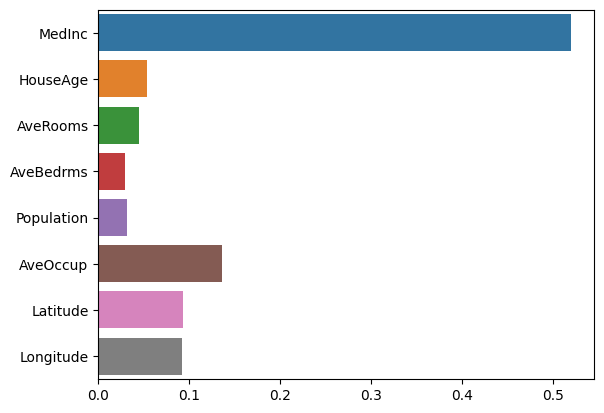

In [10]:
# 10. 랜덤 포레스트가 계산한 특성 중요도를 막대그래프로 확인합니다.
# fit은 전체 X_data와 y_target으로 모델을 학습합니다.

# 특성 중요도는 인과관계를 뜻하지 않으며, 상관이 큰 특성끼리는 중요도를 나눠 가질 수 있습니다.

import seaborn as sns

rf = RandomForestRegressor(n_estimators= 1000, n_jobs = -1,)
rf.fit(X_data, y_target)

# feature_importances_는 트리의 분기에서 각 입력 특성이 기여한 상대적 중요도입니다.
# Series로 중요도 값과 특성 이름을 연결하면 어느 열의 값인지 알기 쉽습니다.
feature_series = pd.Series(data = rf.feature_importances_, index = X_data.columns)
features_series = feature_series.sort_values(ascending=False)
sns.barplot(x=feature_series, y= feature_series.index)

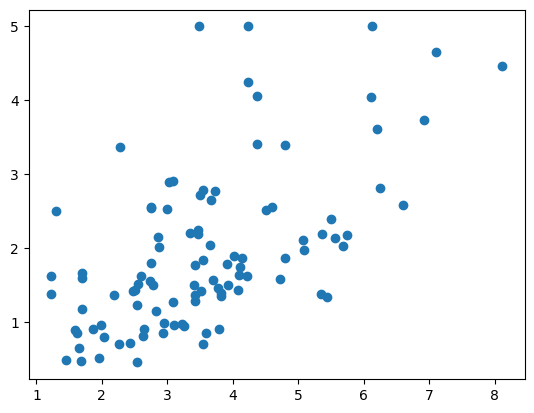

In [11]:
# 11. 소득(MedInc)과 주택 가격(PRICE)의 관계를 표본 100개로 산점도에 표시합니다.

# df에서 관심 있는 두 열만 골라 df_sample이라는 새 표를 만듭니다.
 # sample은 무작위 표본을 뽑고 random_state를 고정해 같은 행이 선택되도록 합니다.
# scatter의 x축은 중위 소득, y축은 주택 가격입니다.
# 표본만 그리므로 전체 20,640개 지역의 모든 점을 그릴 때보다 화면이 덜 복잡합니다.

import matplotlib.pyplot as plt

df_sample =df[["MedInc","PRICE"]]
df_sample =  df_sample.sample(n = 100 , random_state = 42)
plt.figure()
plt.scatter(df_sample["MedInc"], df_sample["PRICE"])

In [12]:
# 12. 같은 표본에 직선 회귀와 깊이가 다른 결정 트리를 맞추고 예측선을 계산합니다.

# 아래 그래프 셀도 세 칸 모두 pred_lr를 그리므로 트리 곡선을 비교하지 못합니다. 주석으로 이 점을 표시했습니다.

import numpy as np
from sklearn.linear_model import LinearRegression

# LinearRegression은 직선, DecisionTreeRegressor는 구간별 규칙을 학습합니다.
# max_depth가 커지면 트리가 더 복잡한 구간을 만들 수 있습니다.
lr = LinearRegression()
dt1 = DecisionTreeRegressor(max_depth=2)
dt2 = DecisionTreeRegressor(max_depth=7)

# arange는 소득값 1.0부터 10.0 직전까지 0.09 간격의 시험 x값들을 만듭니다.
# reshape(-1, 1)은 sklearn 입력 모양(표본 수, 특성 1개)으로 맞춥니다.
X_test = np.arange(1.0 , 10.0, 0.09).reshape(-1, 1)

# X_feature와 y_target도 같은 표본 순서로 2차원 배열로 바꿉니다.
X_feature = df_sample["MedInc"].values.reshape(-1,1)
y_target = df_sample["PRICE"].values.reshape(-1,1)

# 세 모델을 fit으로 학습한 뒤 각 모델의 predict로 예측선을 만들어야 합니다.
lr.fit(X_feature, y_target)
dt1.fit(X_feature, y_target)
dt2.fit(X_feature, y_target)


pred_lr = lr.predict(X_test)
pred_dt1 = dt1.predict(X_test) 
pred_dt2 = dt2.predict(X_test) 

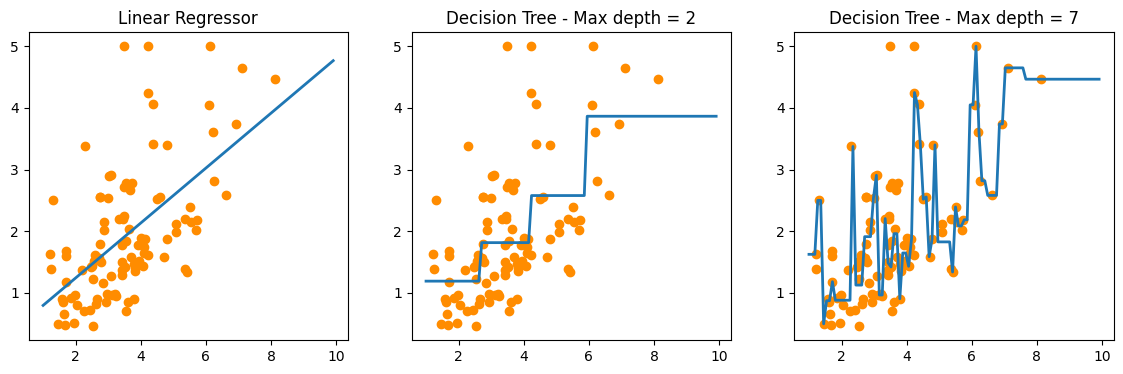

In [13]:
# 13. 직선 모델과 트리 모델의 예측을 세 그래프에서 비교하려는 셀입니다.

# 각 칸에 같은 표본 점을 그리고, plot으로 모델 예측선을 표시합니다.
# 원본에서는 세 plot 모두 pred_lr를 사용하고 있어 제목과 그려진 선이 맞지 않습니다.

# 11번 셀의 pred_dt2도 dt1의 예측값으로 잘못 지정되어 있으므로 두 곳을 함께 고쳐야 올바른 비교가 됩니다.

# subplots는 한 행에 세 개의 그래프 칸과 각 칸의 축 객체(ax1, ax2, ax3)를 만듭니다.
fig,  (ax1,ax2,ax3) = plt.subplots(figsize = (14,4),ncols = 3)
ax1.set_title("Linear Regressor")
ax1.scatter(df_sample.MedInc, df_sample.PRICE, c="darkorange")
ax1.plot(X_test, pred_lr, label = "linear", linewidth = 2)

ax2.set_title("Decision Tree - Max depth = 2")
ax2.scatter(df_sample.MedInc, df_sample.PRICE, c="darkorange")
ax2.plot(X_test, pred_dt1, label = "linear", linewidth = 2)

ax3.set_title("Decision Tree - Max depth = 7")
ax3.scatter(df_sample.MedInc, df_sample.PRICE, c="darkorange")
ax3.plot(X_test, pred_dt2, label = "linear", linewidth = 2)